-incorporate n
-varimax understand
-sparsity check
-11+4
- parameters-label/boldify
- vectors step 


In [61]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

# Functions with different n values

In [62]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [63]:

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [65]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_332_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (332, 28)
Number of samples: 332
Number of parameters per sample: 28


# Stability check

In [35]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [36]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 8 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 8 samples for analysis


In [37]:
# Analyze stability for each n combination

stability_results_all = {}

n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562

 
stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    # Get fixed point outputs with new n values
    try:
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

        # Construct state vector s* = [r, g, y]
        s_star = jnp.concatenate([r_star, g_star, y_star])

        # Verify it's a fixed point
        s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)

        if s_error > 1e-3:
            print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

        # Compute stability
        result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue


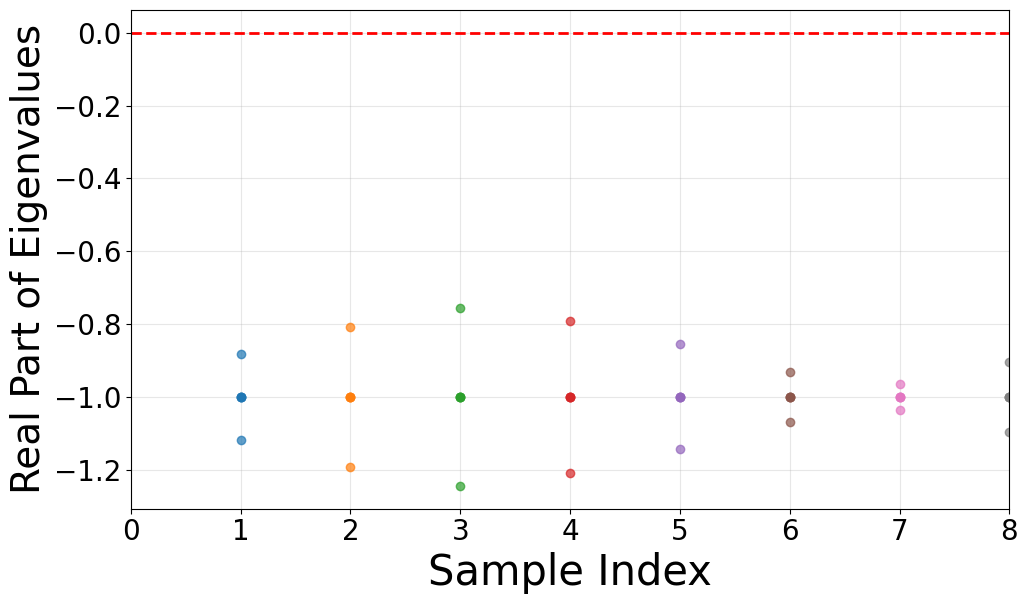


STABILITY SUMMARY

Stable samples: 8/8 (100.0%)


In [38]:
# visualise stability results
fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

# use actual number of samples
actual_no_samples = len(stability_results)
for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i+1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i+1}' if i < 5 else '')
ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=30)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
actual_no_samples = len(stability_results)
ax1.set_xlim(0, actual_no_samples)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])
unstable_count = actual_no_samples - stable_count

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.savefig('Figures/stability.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)
print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100*stable_count/actual_no_samples:.1f}%)")

In [42]:
# remove unstable theta
theta_opt = np.array(theta_opt)

# Identify unstable samples from stability_results
remove_row = [i for i, r in enumerate(stability_results) if not r['is_stable']]

max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)

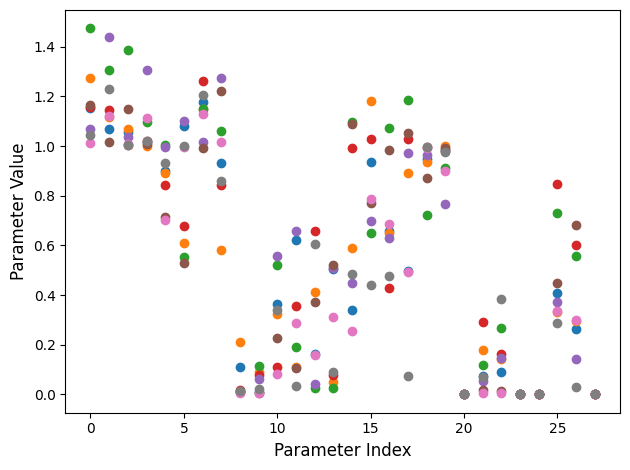

In [39]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

Processing 8 samples...
  Sample 1/8...
Completed processing 8 samples


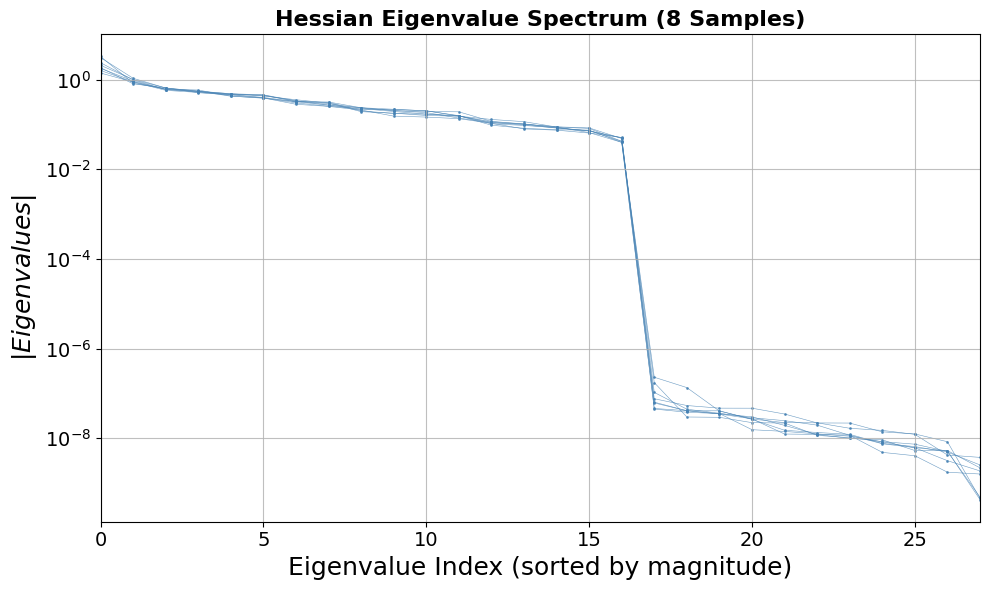

In [44]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [45]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)
    
    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)
    
    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)
    
    return eigenvectors_subspace2

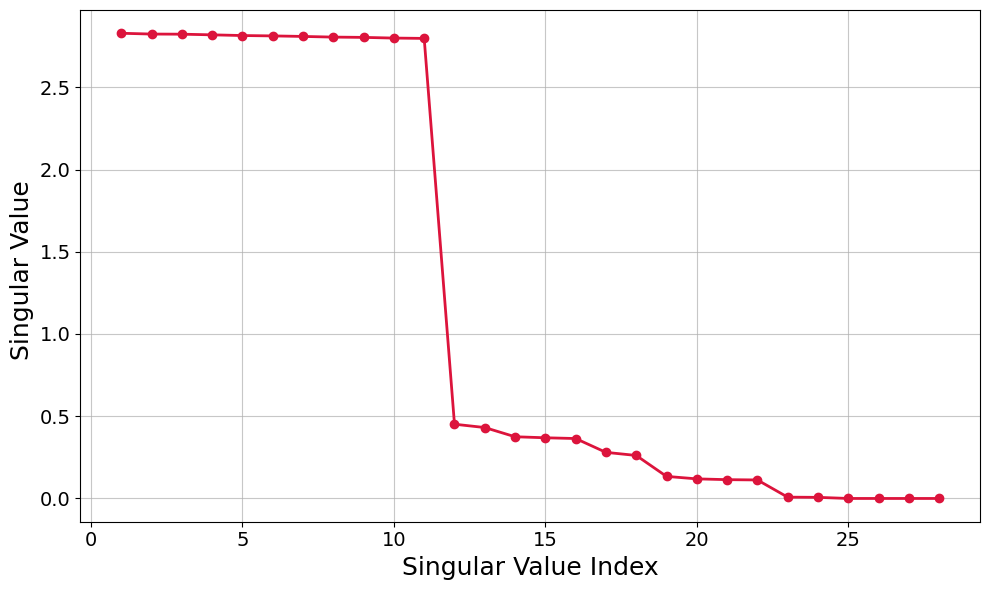

In [46]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(S)+1), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

# Varimax Rotation - How It Works

## The Goal
Varimax rotation finds a new coordinate system (rotation) for your data that makes the components **simpler to interpret**. It does this by making each component have:
- **Some parameters with large values** (close to ±1)
- **Most parameters with small values** (close to 0)

This creates a "sparse" representation where each component is clearly associated with a few parameters.

## The Process (Step by Step)

1. **Start with matrix Q**: You have a matrix Q with orthonormal columns (like principal components from SVD)

2. **Find a rotation matrix R**: Varimax finds an orthogonal rotation matrix R such that when you rotate Q:
   ```
   M = Q @ R
   ```
   The columns of M have high variance in their squared values.

3. **Why squared values?**: 
   - High variance in squared values means: some entries are large, most are small
   - This makes each component "specialized" - it's strongly associated with only a few parameters

4. **The Algorithm**:
   - **Initialize**: Start with R = identity matrix (no rotation)
   - **Iterate**:
     - Compute rotated matrix: M = Q @ R
     - Compute a "gradient" that pushes toward sparsity: 
       ```
       Lambda = M * (M² - mean(M²))
       ```
       This term is large when M² is far from its mean (encouraging some large, some small values)
     - Update rotation: Use SVD to find the best orthogonal rotation that increases sparsity
   - **Stop**: When the rotation stops changing (converged)

## What You Get

After rotation, each column of M represents a component where:
- **A few parameters have large absolute values** → This component is "about" those parameters
- **Most parameters have small values** → This component doesn't care about those parameters

This makes it much easier to interpret what each component represents!

## In Your Context

You're using Varimax on eigenvectors from the Hessian (directions where the output doesn't change). After rotation:
- Each rotated component will be clearly associated with specific parameter combinations
- This helps identify which parameter directions are "degenerate" (don't affect output)

In [50]:
def varimax(Q, gamma=1.0, q=20, tol=1e-6):
    """
    Orthogonal varimax rotation.

    Parameters
    ----------
    Q : array, shape (n, k)
        Matrix with orthonormal columns.
    gamma : float
        Varimax parameter. gamma=1.0 is standard varimax.
        gamma=0.0 gives quartimax.
    q : int
        Maximum number of iterations.
    tol : float
        Convergence tolerance.

    Returns
    -------
    M : array, shape (n, k)
        Rotated matrix (Q @ R).
    R : array, shape (k, k)
        Orthogonal rotation matrix.
    """
    n, k = Q.shape
    R = np.eye(k)
    d = 0

    for i in range(q):
        d_old = d

        # rotated loadings
        M = Q @ R

        # gradient-like update
        # diag term enforces column-wise normalization
        Lambda = M * (M**2 - gamma * np.mean(M**2, axis=0, keepdims=True))

        # SVD-based orthogonal update
        U, S, Vt = np.linalg.svd(Q.T @ Lambda)
        R = U @ Vt

        d = np.sum(S)
        if d_old != 0 and d / d_old < 1 + tol:
            break

    return Q @ R, R


In [ ]:
Q = U[:11].T
# Initialize variables to track the best varimax rotation found
best_M, best_R = None, None
best_score = -np.inf

# Try 10 different random starting rotations
# Why? Varimax can get stuck in local optima, so trying multiple random starts
# helps us find a better (more sparse) solution
for _ in range(10):
    # Create a random orthogonal rotation matrix using QR decomposition
    # This gives us a random starting point for varimax
    R0, _ = np.linalg.qr(np.random.randn(Q.shape[1], Q.shape[1]))
    
    # Apply the random rotation first, then run varimax on the rotated Q
    # This explores different regions of the rotation space
    M, R = varimax(Q @ R0)
    
    # Score the result: sum of absolute values
    # Higher score = more sparse (more large values, fewer small ones)
    # This measures how "specialized" each component is
    score = np.sum(np.abs(M))
    
    # Keep track of the best rotation found so far
    if score > best_score:
        best_score = score
        best_M, best_R = M, R @ R0  # R @ R0 combines both rotations

# Standardize signs: make the sum of each column positive
# This ensures consistent orientation (no arbitrary sign flips)
signs = np.sign(np.sum(best_M, axis=0))
best_M *= signs  # Flip columns of M if needed
best_R *= signs  # Apply same sign flips to rotation matrix


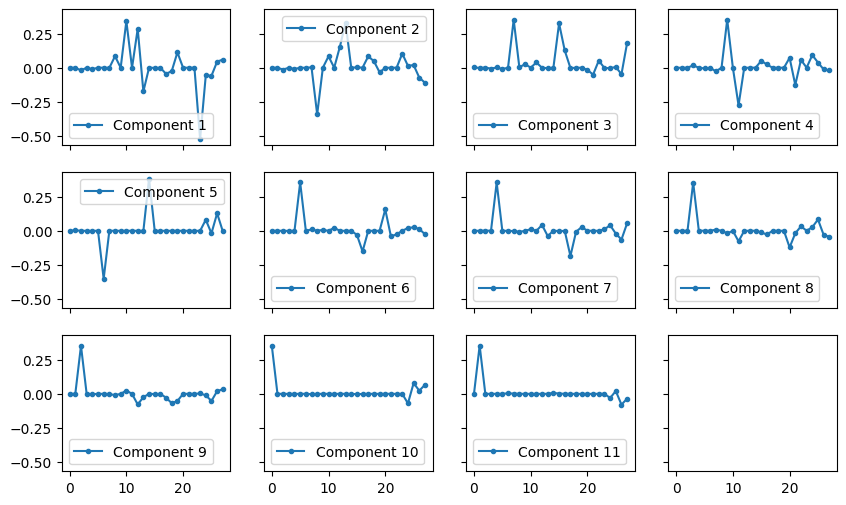

In [53]:
fig, ax = plt.subplots(figsize=(10, 6), nrows=3, ncols=4, sharex=True, sharey=True)
M_sums = np.abs(best_M).sum(0)
sorting_ind = np.argsort(M_sums)[::-1]
M_plot = best_M[:, sorting_ind]
for i in range(11):
    ax[i//4, i%4].plot(M_plot[:, i], '.-', label=f'Component {i+1}')
    ax[i//4, i%4].legend()
# plt.tight_layout()
plt.show()


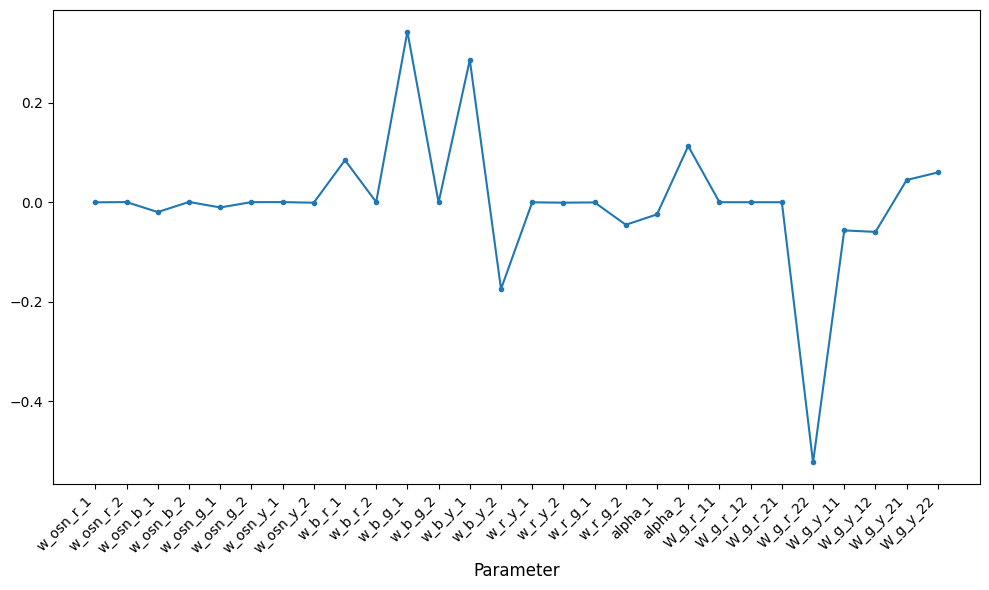

In [60]:

plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 0], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()